# LLM local contre modèle spécialisé : sentiment et thèmes d'avis en français

Ce notebook présente une analyse d'avis entièrement exécutée en local, sur une carte NVIDIA GTX 1060 (6 Go de VRAM). Elle compare deux familles de modèles :

- **Mistral 7B**, un LLM généraliste quantifié sur 4 bits, servi par Ollama et utilisé sans exemple ;
- **BERT nlptown** (`nlptown/bert-base-multilingual-uncased-sentiment`), un modèle spécialisé qui note un avis de 1 à 5 étoiles.

Deux tâches sont traitées sur 500 critiques de films Allociné : la **classification de sentiment** et l'**extraction de thèmes**.

### À retenir

- **La première comparaison était biaisée.** Mistral, forcé à répondre « positif » ou « négatif », obtenait 89,2 % contre 91,8 % pour BERT. Mais BERT pouvait écarter les avis ambigus (note 3/5) alors que Mistral devait trancher.
- **Sur les mêmes avis, les deux modèles se valent** : 98,2 % pour Mistral et 96,2 % pour BERT. L'écart n'est pas significatif (test de McNemar, p = 0,077).
- **La consigne compte surtout par ce qu'elle fait à l'évaluation.** Passer de la consigne binaire à l'échelle 1-5 n'apporte qu'environ 1 point sur des avis identiques. Le saut apparent venait de l'exclusion des avis difficiles.
- **Coût.** Mistral occupe presque toute la VRAM et il est environ 15 fois plus lent que BERT.
- **Thèmes.** KeyBERT a d'abord échoué silencieusement : il n'encodait que 0,6 % du texte. La catégorisation par LLM est plus exploitable, mais elle ne peut pas être évaluée sans vérité terrain.

### Comment lire ce notebook

Les inférences (Mistral, BERT, KeyBERT) ont été faites par les scripts numérotés du dossier `scripts/`, et leurs sorties sont enregistrées dans `data/` et `resultats/`. Ce notebook ne fait que relire ces fichiers : il s'exécute en quelques secondes, sans GPU ni Ollama.

In [1]:
import json
import textwrap

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

import sys
sys.path.insert(0, "scripts")  # fonctions communes dans scripts/
from outils_eval import (accuracy, binariser, bootstrap_diff, normaliser_binaire,
                         note_bert, parse_note, tableau_effet_prompt)

pd.set_option("display.max_colwidth", 110)
BLEU, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False})


def fr(x, d=1):
    # 14.4 -> '14,4' (décimale à la française)
    return f"{x:.{d}f}".replace(".", ",")


def pct(x, d=1):
    # 0.8917 -> '89,2 %'
    return f"{fr(100 * x, d)} %"


def acc_txt(y, pred):
    k, n, a, (lo, hi) = accuracy(y, pred)
    return f"{pct(a)} ({k}/{n}), IC 95 % [{pct(lo)} ; {pct(hi)}]"

## 1. Données

Les verbatims clients réels n'étaient pas exploitables : ils contiennent des données personnelles, et les plateformes d'avis encadrent leur extraction. Le corpus public **Allociné** (`tblard/allocine`, licence MIT) sert de substitut. Son label dérive de la note donnée par l'auteur : une note inférieure ou égale à 2/5 donne un avis négatif, une note supérieure ou égale à 4/5 un avis positif. Les notes intermédiaires sont absentes, si bien que **la vérité terrain n'a pas de classe neutre**.

Le script `scripts/01_dataset.py` tire du découpage de test un échantillon stratifié de 500 avis, avec une graine fixe.

In [2]:
ech = pd.read_csv("data/allocine_sample.csv")
ech["id"] = range(len(ech))
longueur = ech["review"].str.len()

print(f"{len(ech)} avis : {(ech.label == 0).sum()} négatifs, {(ech.label == 1).sum()} positifs")
print(f"Longueur médiane : {longueur.median():.0f} caractères "
      f"({ech.review.str.split().str.len().median():.0f} mots), maximum : {longueur.max()} caractères")

# Quelques avis courts, pour se faire une idée
ech[longueur < 160].groupby("label").sample(2, random_state=3)[["label", "review"]]

500 avis : 250 négatifs, 250 positifs
Longueur médiane : 376 caractères (64 mots), maximum : 1987 caractères


,label,review
203,0,"Dommage! J'avais hate de voir la suite, et j'ai été bien deçu. On s'ennuie à mourir."
83,0,"L’histoire de ce film sonne creux du début jusqu'à la fin. C’est ennuyeux, insipide et monotone. Surtout à..."
258,1,"Une bonne comédie des inconnues, bon divertissement."
372,1,un des rares films francais qui tient bien la route et qui fait bien peur =)


## 2. Choisir ses modèles en fonction du matériel

En exécution locale, la question devient : quel est le meilleur modèle **qui tient sur la machine** ? Un LLM occupe environ $N \times b/8$ octets de poids, où $N$ est le nombre de paramètres et $b$ le nombre de bits par paramètre. S'y ajoutent un cache proportionnel à la longueur du contexte et des tampons de calcul.

In [3]:
N = 7.2e9  # paramètres de Mistral 7B
for precision, bits in [("FP16", 16), ("Q8_0 (8 bits)", 8.5), ("Q4_K_M (4 bits, retenu)", 4.9)]:
    print(f"{precision:24s} {fr(N * bits / 8 / 1e9):>5s} Go de poids")

# Cache clés/valeurs : 2 (K et V) x 32 couches x 8 têtes K/V x 128 dimensions x 2 octets
par_token = 2 * 32 * 8 * 128 * 2
print(f"\nCache : {par_token // 1024} Kio par token, soit {par_token * 4096 / 2**20:.0f} Mio pour 4 096 tokens")

vram = json.load(open("mesures/resultats/mesure_vram.json"))
total, sur_gpu = vram["ollama_ps"]["taille_octets"], vram["ollama_ps"]["taille_vram_octets"]
print(f"\nMesuré : VRAM totale {vram['vram_totale_mio']} Mio, dont {vram['vram_repos_mio']} Mio pris par l'affichage")
print(f"Mistral chargé : {fr(total / 1e9, 2)} Go, dont {fr(sur_gpu / 1e9, 2)} Go sur le GPU ({pct(sur_gpu / total, 0)})")
print(f"BERT : {vram['bert_parametres'] / 1e6:.0f} M de paramètres, "
      f"{vram['bert_pic_inference_mio']} Mio au maximum pendant l'inférence")

FP16                      14,4 Go de poids
Q8_0 (8 bits)              7,7 Go de poids
Q4_K_M (4 bits, retenu)    4,4 Go de poids

Cache : 128 Kio par token, soit 512 Mio pour 4 096 tokens

Mesuré : VRAM totale 6144 Mio, dont 749 Mio pris par l'affichage
Mistral chargé : 5,06 Go, dont 4,34 Go sur le GPU (86 %)
BERT : 167 M de paramètres, 915 Mio au maximum pendant l'inférence


Sur 6 Go, seule une version de Mistral 7B quantifiée sur 4 bits est envisageable, et elle dépasse encore légèrement la mémoire libre : environ 14 % du modèle tourne sur le CPU. Cela reste utilisable parce que les réponses demandées sont très courtes. BERT est 43 fois plus petit et laisse une large marge. Le choix ne s'arrête pas à la mémoire : le modèle d'embeddings que KeyBERT utilise par défaut tient sans difficulté, mais il est entraîné sur l'anglais, ce qui pèse sur l'extraction de thèmes (section 4).

## 3. Sentiment : un biais d'évaluation, puis sa vérification

La première consigne donnée à Mistral l'oblige à trancher (`scripts/02_sentiment_llm.py`) :

```text
Classe le sentiment de cet avis de film.
Réponds uniquement par un seul mot : positif ou négatif.
```

BERT (`scripts/04_sentiment_bert.py`) donne nativement une note de 1 à 5 étoiles. Les notes 1 et 2 comptent comme négatives, 4 et 5 comme positives, et **un avis noté 3 est exclu**.

In [4]:
bert = pd.read_csv("data/resultats_bert.csv")
mb = pd.read_csv("data/resultats_llm_500.csv").set_index("id").sort_index()        # consigne binaire
ms = pd.read_csv("data/resultats_llm_stars_500.csv").set_index("id").sort_index()  # échelle 1-5
assert (bert.review.values == ech.review.values).all() and (mb.index == ech.id).all()

df500 = pd.DataFrame({
    "label": ech["label"],
    "m_bin": mb["pred_brut"].apply(normaliser_binaire).values,
    "m_note": ms["note_brute"].apply(parse_note).values,
    "b_note": bert["note_brute"].apply(note_bert).values,
})

# Les 120 avis du premier passage (scripts 02 et 08), retrouvés par leur texte
llm = pd.read_csv("data/resultats_llm.csv")
stars = pd.read_csv("data/resultats_llm_stars.csv")
ids120 = llm["review"].map(dict(zip(ech.review, ech.id))).values
df120 = pd.DataFrame({
    "label": llm["label"].values,
    "m_bin": llm["pred_brut"].apply(normaliser_binaire).values,
    "m_note": stars["note_brute"].apply(parse_note).values,
    "b_note": df500.loc[ids120, "b_note"].values,
})
df500.head()

,label,m_bin,m_note,b_note
0,0,0,2,2
1,0,0,3,3
2,0,0,3,3
3,0,0,1,2
4,0,0,1,2


### 3.1 Itération 1 : une comparaison biaisée

Le premier test portait sur un sous-échantillon de 120 avis.

In [5]:
d = df120.assign(b_bin=df120.b_note.apply(binariser), m_note_bin=df120.m_note.apply(binariser))
garde_bert = d.b_bin.notna()

print("Mistral, consigne binaire       :", acc_txt(d.label, d.m_bin))
print("BERT, échelle 1-5 (hors notes 3):", acc_txt(d.label[garde_bert], d.b_bin[garde_bert]))

Mistral, consigne binaire       : 89,2 % (107/120), IC 95 % [82,3 % ; 93,6 %]
BERT, échelle 1-5 (hors notes 3): 91,8 % (90/98), IC 95 % [84,7 % ; 95,8 %]


À première lecture, BERT est meilleur. Pourtant, les deux chiffres ne portent pas sur les mêmes avis : BERT a écarté les 22 avis qu'il notait 3, alors que Mistral devait trancher partout. Or les avis ambigus sont précisément les plus difficiles.

In [6]:
print("Mistral binaire, sur les 98 avis gardés par BERT  :", acc_txt(d.label[garde_bert], d.m_bin[garde_bert]))
print("Mistral binaire, sur les 22 avis écartés par BERT :", acc_txt(d.label[~garde_bert], d.m_bin[~garde_bert]))

Mistral binaire, sur les 98 avis gardés par BERT  : 92,9 % (91/98), IC 95 % [86,0 % ; 96,5 %]
Mistral binaire, sur les 22 avis écartés par BERT : 72,7 % (16/22), IC 95 % [51,8 % ; 86,8 %]


Sur le périmètre de BERT, Mistral fait aussi bien que lui. Il ne perd des points que sur les avis que BERT s'est permis d'écarter : **le protocole récompensait l'abstention**.

### 3.2 Itération 2 : la même échelle pour les deux modèles

Mistral reçoit alors la même échelle que BERT, sur les mêmes 120 avis (`scripts/08_sentiment_llm_stars.py`), avec la même règle : un avis noté 3 est exclu.

```text
Note cet avis de film sur une échelle de 1 à 5 :
1 = très négatif, 2 = négatif, 3 = neutre/mitigé, 4 = positif, 5 = très positif.
Réponds uniquement par un chiffre entre 1 et 5, sans aucun autre texte.
```

In [7]:
tranche = d.m_note_bin.notna()
print(f"Mistral note 3 : {(~tranche).sum()} avis sur 120")
print("Mistral, échelle 1-5 (hors notes 3) :", acc_txt(d.label[tranche], d.m_note_bin[tranche]))

Mistral note 3 : 16 avis sur 120
Mistral, échelle 1-5 (hors notes 3) : 96,2 % (100/104), IC 95 % [90,5 % ; 98,5 %]


Le classement s'inverse : Mistral (96,2 %) passe devant BERT (91,8 %). Mais cette comparaison porte encore sur des ensembles différents, 104 avis d'un côté et 98 de l'autre.

### 3.3 Vérification : sur les mêmes avis, puis sur 500 avis

Deux questions restent ouvertes : les méthodes se départagent-elles sur des avis identiques, et un écart de quelques points dépasse-t-il le hasard ? Sur 120 avis, un tel écart ne repose que sur une poignée d'avis. Mistral a donc été relancé avec les deux consignes sur les 500 avis (`scripts/14_mistral_500.py`), cette fois avec une graine fixe : les scripts d'origine l'appelaient sans graine.

Les 120 avis du premier test font partie des 500. La relance permet d'abord de vérifier que Mistral répond de la même façon d'un passage à l'autre :

In [8]:
# Les 120 avis du premier test, retrouvés dans la relance sur 500 avis
relance = df500.loc[ids120]
print(f"Prédictions binaires identiques entre les deux passages : {pct((relance.m_bin.values == df120.m_bin.values).mean())}")
print(f"Notes 1-5 identiques entre les deux passages            : {pct((relance.m_note.values == df120.m_note.values).mean())}")
print(f"\nMistral binaire, premier passage : {acc_txt(df120.label, df120.m_bin)}")
print(f"Mistral binaire, relance         : {acc_txt(df120.label, relance.m_bin)}")

Prédictions binaires identiques entre les deux passages : 97,5 %
Notes 1-5 identiques entre les deux passages            : 95,0 %

Mistral binaire, premier passage : 89,2 % (107/120), IC 95 % [82,3 % ; 93,6 %]
Mistral binaire, relance         : 91,7 % (110/120), IC 95 % [85,3 % ; 95,4 %]


Quelques réponses changent d'un passage à l'autre, et cela suffit à déplacer l'accuracy binaire de 2,5 points sur 120 avis. C'est une raison de plus pour fixer la graine et pour raisonner sur 500 avis.

Chaque méthode est ensuite réévaluée sur des avis identiques, sur les 120 avis puis sur les 500 :

- **(a)** : la consigne binaire, restreinte aux avis que Mistral 1-5 tranche ;
- **(b)** : les trois méthodes, sur le sous-ensemble tranché à la fois par Mistral 1-5 et par BERT.

In [9]:
acc120, tests120, _ = tableau_effet_prompt(df120)
acc500, tests500, eff500 = tableau_effet_prompt(df500)

tableau = acc120[["perimetre", "methode"]].rename(columns={"perimetre": "Périmètre", "methode": "Méthode"})
for nom, a in [("120 avis", acc120), ("500 avis", acc500)]:
    tableau[nom] = [f"{pct(r.accuracy)} ({r.corrects}/{r.n})" for r in a.itertuples()]
tableau

,Périmètre,Méthode,120 avis,500 avis
0,Tous les avis exploitables,Mistral binaire,"89,2 % (107/120)","93,6 % (468/500)"
1,Avis non neutres pour Mistral 1-5,Mistral 1-5,"96,2 % (100/104)","96,9 % (431/445)"
2,Avis non neutres pour BERT,BERT 1-5,"91,8 % (90/98)","95,5 % (403/422)"
3,(a) Avis non neutres pour Mistral 1-5,Mistral binaire,"91,3 % (95/104)","96,0 % (427/445)"
4,(b) Sous-ensemble commun,Mistral binaire,"94,5 % (86/91)","97,2 % (388/399)"
5,(b) Sous-ensemble commun,Mistral 1-5,"96,7 % (88/91)","98,2 % (392/399)"
6,(b) Sous-ensemble commun,BERT 1-5,"92,3 % (84/91)","96,2 % (384/399)"


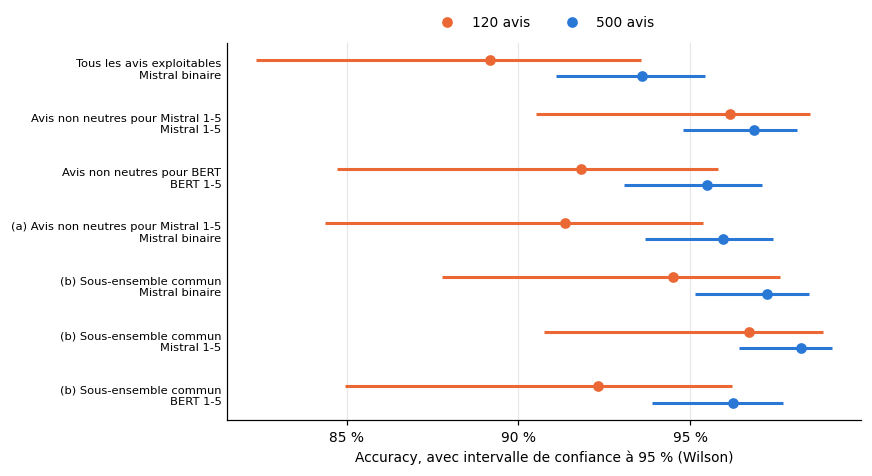

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.4))
etiquettes = [f"{p}\n{m}" for p, m in zip(acc120.perimetre, acc120.methode)]
y = np.arange(len(etiquettes))[::-1]
for dy, a, couleur, nom in [(0.15, acc120, ORANGE, "120 avis"), (-0.15, acc500, BLEU, "500 avis")]:
    ax.hlines(y + dy, a.ic95_bas, a.ic95_haut, color=couleur, lw=2)
    ax.plot(a.accuracy, y + dy, "o", color=couleur, label=nom)
ax.set_yticks(y, etiquettes, fontsize=7.5)
ax.xaxis.set_major_locator(mticker.MultipleLocator(0.05))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: pct(v, 0)))
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Accuracy, avec intervalle de confiance à 95 % (Wilson)")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
plt.tight_layout()
plt.show()

Pour savoir si un écart entre deux méthodes est réel, on les compare sur les mêmes avis avec un **test de McNemar**. Ce test ne regarde que les paires discordantes : les avis où une méthode a raison et l'autre tort.

In [11]:
tests = tests500[["perimetre", "A", "B", "n", "A_juste_B_faux", "A_faux_B_juste"]].copy()
tests["p (500 avis)"] = tests500["p_mcnemar"].round(3)
tests["p (120 avis)"] = tests120["p_mcnemar"].round(3)
tests.columns = ["Périmètre", "A", "B", "Avis", "A seul juste", "B seul juste", "p (500 avis)", "p (120 avis)"]
tests

,Périmètre,A,B,Avis,A seul juste,B seul juste,p (500 avis),p (120 avis)
0,(a) Avis non neutres pour Mistral 1-5,Mistral 1-5,Mistral binaire,445,5,1,0.219,0.062
1,(b) Sous-ensemble commun,Mistral 1-5,Mistral binaire,399,4,0,0.125,0.500
2,(b) Sous-ensemble commun,Mistral 1-5,BERT 1-5,399,12,4,0.077,0.219
3,(b) Sous-ensemble commun,Mistral binaire,BERT 1-5,399,12,8,0.503,0.727


In [12]:
# Intervalle bootstrap apparié (10 000 tirages) de la différence d'accuracy, sur le sous-ensemble commun
c = df500.assign(m_note_bin=df500.m_note.apply(binariser), b_bin=df500.b_note.apply(binariser))
c = c.dropna(subset=["m_note_bin", "b_bin"])
for a, b, na, nb in [("m_note_bin", "b_bin", "Mistral 1-5", "BERT"),
                     ("m_bin", "b_bin", "Mistral binaire", "BERT"),
                     ("m_note_bin", "m_bin", "Mistral 1-5", "Mistral binaire")]:
    diff, lo, hi = bootstrap_diff(c.label, c[a], c[b])
    print(f"{na:15s} - {nb:15s} : {fr(100 * diff):>4s} point(s), IC 95 % [{fr(100 * lo)} ; {fr(100 * hi)}]")

Mistral 1-5     - BERT            :  2,0 point(s), IC 95 % [0,0 ; 4,0]
Mistral binaire - BERT            :  1,0 point(s), IC 95 % [-1,3 ; 3,3]
Mistral 1-5     - Mistral binaire :  1,0 point(s), IC 95 % [0,3 ; 2,0]


**Ce qu'il faut retenir.**

- **La consigne a fait paraître le LLM moins bon, pas sa compréhension.** Comparé sur les mêmes avis que BERT, Mistral avec la consigne binaire n'est pas inférieur : 97,2 % contre 96,2 % (p = 0,50).
- **Le gain de l'itération 2 vient surtout de l'exclusion des cas difficiles.** Sur 500 avis, la consigne binaire atteint déjà 96,0 % sur les 445 avis que l'échelle 1-5 tranche, contre 96,9 % pour l'échelle 1-5 (p = 0,22). L'effet propre de la formulation est d'environ 1 point. Son intervalle bootstrap exclut 0, mais il repose sur seulement 4 paires discordantes : le test exact prévaut.
- **À périmètre égal, Mistral et BERT se valent.** L'avantage de Mistral 1-5 (+2 points, 12 paires discordantes contre 4) va dans le même sens sur 120 et sur 500 avis, sans être significatif (p = 0,077).

### 3.4 Les deux modèles ne s'abstiennent pas sur les mêmes avis

Mistral note 3 : 55 avis (48 réellement négatifs)
BERT note 3    : 78 avis (42 réellement négatifs)
Notés 3 par les deux : 32


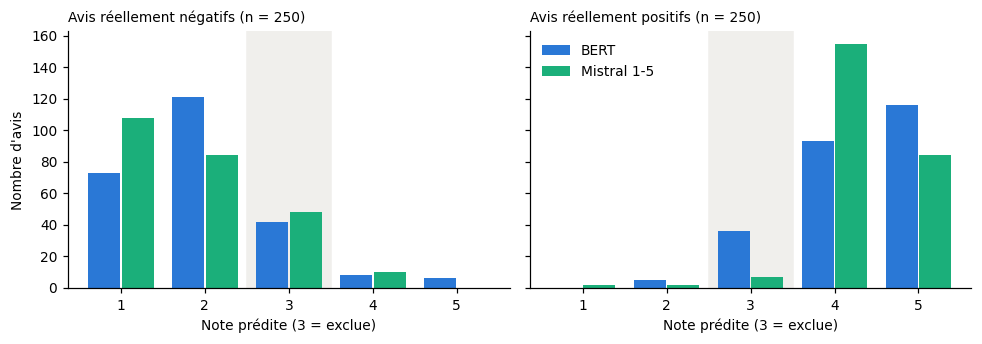

In [13]:
m3, b3 = df500.m_note == 3, df500.b_note == 3
print(f"Mistral note 3 : {m3.sum()} avis ({(m3 & (df500.label == 0)).sum()} réellement négatifs)")
print(f"BERT note 3    : {b3.sum()} avis ({(b3 & (df500.label == 0)).sum()} réellement négatifs)")
print(f"Notés 3 par les deux : {(m3 & b3).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
x = np.arange(1, 6)
for ax, lab, titre in [(axes[0], 0, "Avis réellement négatifs"), (axes[1], 1, "Avis réellement positifs")]:
    sub = df500[df500.label == lab]
    for dx, col, nom, couleur in [(-0.2, "b_note", "BERT", BLEU), (0.2, "m_note", "Mistral 1-5", AQUA)]:
        ax.bar(x + dx, sub[col].value_counts().reindex(x, fill_value=0), 0.38, color=couleur, label=nom)
    ax.axvspan(2.5, 3.5, color="#f0efec", zorder=0)
    ax.set_title(f"{titre} (n = {len(sub)})", loc="left", fontsize=9)
    ax.set_xlabel("Note prédite (3 = exclue)")
axes[0].set_ylabel("Nombre d'avis")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

Mistral perçoit comme mitigées des critiques négatives nuancées ; BERT hésite de façon symétrique. Il en découle un compromis entre couverture et précision. Si chaque avis doit recevoir une étiquette, les exclusions comptent comme des erreurs :

In [14]:
for nom, pred in [("Mistral binaire", df500.m_bin),
                  ("Mistral 1-5", df500.m_note.apply(binariser)),
                  ("BERT 1-5", df500.b_note.apply(binariser))]:
    print(f"{nom:16s} couverture {pct(pred.notna().mean(), 0):>6s}   "
          f"accuracy stricte {pct((pred == df500.label).mean())}")

Mistral binaire  couverture  100 %   accuracy stricte 93,6 %
Mistral 1-5      couverture   89 %   accuracy stricte 86,2 %
BERT 1-5         couverture   84 %   accuracy stricte 80,6 %


## 4. Extraction de thèmes

### 4.1 KeyBERT : trois versions successives

KeyBERT classe des n-grammes candidats selon leur similarité avec l'embedding du document. La v1 (`scripts/10_keywords.py`) concatène tous les avis d'une même polarité en un seul document, puis en extrait les 15 expressions d'un ou deux mots les plus proches.

In [15]:
def lire_keybert(chemin):
    # Sorties console des scripts 10, enregistrées dans mesures/resultats/
    blocs, courant = {}, None
    for ligne in open(chemin, encoding="utf-8"):
        ligne = ligne.strip()
        if ligne.startswith("==="):
            courant = "négatifs" if "NÉGATIFS" in ligne else "positifs"
            blocs[courant] = []
        elif ligne and courant:
            blocs[courant].append(ligne.rsplit(":", 1)[0])
    return blocs


v1 = lire_keybert("mesures/resultats/sortie_10_keywords.txt")
pd.DataFrame({"avis négatifs, v1": v1["négatifs"][:8], "avis positifs, v1": v1["positifs"][:8]})

,"avis négatifs, v1","avis positifs, v1"
0,filmique est,filmsseul petit
1,le cinéma,bien filmées
2,le cinema,le cinéma
3,le film,bien filmé
4,bien film,le film
5,cinématographique qui,filmé dans
6,cinématographique pour,films une
7,les films,dvd pourquoi


Presque tous les termes tournent autour de « film » et de « cinéma » : le vocabulaire commun à toutes les critiques, sans lien avec leur polarité. La v2 (`scripts/10_keywords_v2.py`) exclut donc les mots vides français de NLTK et dix mots propres au domaine (« film », « cinéma », « filmé », « dvd »…).

In [16]:
v2 = lire_keybert("mesures/resultats/sortie_10_keywords_v2.txt")
pd.DataFrame({"avis négatifs, v2": v2["négatifs"][:8], "avis positifs, v2": v2["positifs"][:8]})

,"avis négatifs, v2","avis positifs, v2"
0,particulièrement margot,filmsseul petit
1,entre 16,derniers filmsseul
2,permettre avoir,bon histoire
3,contre laquelle,cette histoire
4,après histoire,entre lelouch
5,histoire passionnante,être petit
6,entre twilight,filmographie jean
7,parvient mettre,histoire passionnante


Les termes sont moins génériques, mais beaucoup renvoient à quelques avis précis (« margot », « twilight », « lelouch ») ou n'ont pas de sens (« filmsseul »). Ils ne résument pas 250 avis. La v3 (`scripts/11_keywords_v3.py`) change d'approche : avec les mêmes exclusions, elle extrait 5 expressions de chaque avis, puis compte leurs occurrences sur l'ensemble des avis d'une polarité.

In [17]:
# Distribution complète de la v3, enregistrée par mesures/keybert_distribution.py
# (même calcul que scripts/11_keywords_v3.py)
v3 = {pol: pd.read_csv(f"mesures/resultats/keybert_v3_distribution_{f}.csv")
      for pol, f in [("négatifs", "negatifs"), ("positifs", "positifs")]}
for pol, kb in v3.items():
    uniques = (kb.occurrences == 1).sum()
    print(f"Avis {pol} : {kb.occurrences.sum()} extractions, {len(kb)} expressions distinctes, "
          f"dont {pct(uniques / len(kb))} vues une seule fois")

pd.DataFrame({f"avis {pol}, v3": [f"{r.terme} ({r.occurrences})" for r in kb.head(8).itertuples()]
              for pol, kb in v3.items()})

Avis négatifs : 1250 extractions, 1199 expressions distinctes, dont 97,6 % vues une seule fois
Avis positifs : 1250 extractions, 1217 expressions distinctes, dont 98,0 % vues une seule fois


,"avis négatifs, v3","avis positifs, v3"
0,peut être (9),peut être (4)
1,histoire (8),très bonne (4)
2,cette histoire (7),hitchcock (3)
3,attendais (4),bon histoire (3)
4,jeu acteurs (4),musique (3)
5,faire foutre (2),fait bien (3)
6,vite (2),très bien (3)
7,intrigue (2),bonne comédie (2)


La v3 fait émerger des signaux pertinents (« histoire », « jeu acteurs », « intrigue »). Mais presque chaque expression n'apparaît qu'une fois, et le bruit reste important : « peut être », noms propres. Chaque amélioration exige d'allonger à la main une liste d'exclusion.

**Pourquoi la v1 et la v2 échouaient : une explication trouvée après coup.** Une mesure faite ensuite (`mesures/diagnostic_troncature.py`) compte les sous-mots du texte concaténé, et la part que le modèle d'embeddings encode réellement :

In [18]:
diag = json.load(open("mesures/resultats/diagnostic_troncature.json", encoding="utf-8"))
for pol in ["negatifs", "positifs"]:
    t = diag[pol]
    n = f"{t['n_tokens']:,}".replace(",", " ")
    part = str(t["part_vue_pct"]).replace(".", ",")
    print(f"Avis {pol.replace('negatifs', 'négatifs')} concaténés : {n} sous-mots, dont {diag['max_seq_length']} encodés "
          f"({part} %), soit {t['avis_entierement_vus']} avis entier(s)")

Avis négatifs concaténés : 39 895 sous-mots, dont 256 encodés (0,64 %), soit 2 avis entier(s)
Avis positifs concaténés : 44 040 sous-mots, dont 256 encodés (0,58 %), soit 1 avis entier(s)


Le modèle d'embeddings tronque son entrée à 256 sous-mots, sans aucun avertissement. Le « document » de la v1 et de la v2 se réduisait donc à un ou deux avis, d'où des termes propres à quelques critiques. La v3 échappe en grande partie à ce problème, puisque chaque avis est encodé séparément.

### 4.2 Catégorisation par LLM

Mistral rattache chaque avis à une catégorie d'une liste fermée :

```text
Voici un avis de film. Identifie la catégorie principale sur laquelle porte la critique,
parmi : scénario, jeu d'acteur, réalisation/mise en scène, rythme, humour, émotion, autre.
Réponds uniquement par le nom de la catégorie, sans explication.
```

Ce prompt a d'abord été testé sur 30 avis (`scripts/12_themes_llm.py`), puis appliqué aux 500 avis avec une graine fixe (`scripts/15_themes_llm_500.py`). Sur les 30 avis communs aux deux passages, 24 reçoivent la même catégorie.

Les réponses brutes ont été normalisées par `scripts/17_analyse_themes.py` : casse, articles, ponctuation et libellés voisins comme « acteur ».

In [19]:
themes = pd.read_csv("resultats/17_themes_normalises.csv")
ordre_statuts = ["conforme brut", "conforme après normalisation de surface", "rattaché par synonyme",
                 "plusieurs catégories", "hors liste"]
conformite = themes.statut.value_counts().reindex(ordre_statuts, fill_value=0).to_frame("avis")
conformite["part"] = (conformite.avis / len(themes)).map(pct)
conformite

,avis,part
statut,,
conforme brut,432,"86,4 %"
conforme après normalisation de surface,2,"0,4 %"
rattaché par synonyme,10,"2,0 %"
plusieurs catégories,48,"9,6 %"
hors liste,8,"1,6 %"


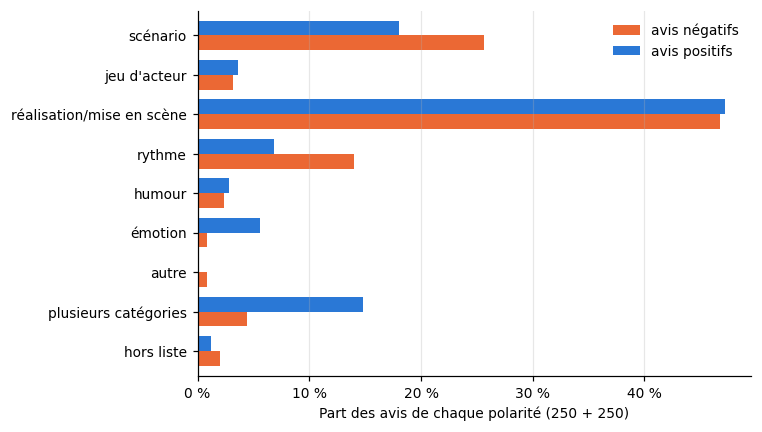

Khi-deux thème x sentiment : chi2 = 32,7, ddl = 6, p = 1.2e-05, V de Cramér = 0,26


In [20]:
ordre = ["scénario", "jeu d'acteur", "réalisation/mise en scène", "rythme", "humour", "émotion",
         "autre", "plusieurs catégories", "hors liste"]
croise = pd.crosstab(themes.categorie, themes.label, normalize="columns").reindex(ordre).fillna(0)
croise.columns = ["avis négatifs", "avis positifs"]

ax = croise[::-1].plot.barh(color=[ORANGE, BLEU], figsize=(7, 4), width=0.75)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: pct(v, 0)))
ax.set_xlabel("Part des avis de chaque polarité (250 + 250)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

effectifs = pd.crosstab(themes.categorie, themes.label)
testables = effectifs[effectifs.sum(axis=1) >= 10]
chi2, p, ddl, _ = chi2_contingency(testables)
v = np.sqrt(chi2 / (testables.values.sum() * (min(testables.shape) - 1)))
print(f"Khi-deux thème x sentiment : chi2 = {fr(chi2)}, ddl = {ddl}, p = {p:.1e}, V de Cramér = {fr(v, 2)}")

Le **scénario** et le **rythme** ressortent dans les avis négatifs, l'**émotion** dans les avis positifs. L'association est significative mais modérée. En revanche, « réalisation/mise en scène » reçoit près de la moitié des avis dans les deux polarités : elle ne distingue rien et fonctionne probablement comme catégorie par défaut.

| | KeyBERT v3 | Catégorisation par LLM |
|---|---|---|
| Sortie | Plus de 1 000 expressions distinctes par polarité | 7 catégories, croisables avec le sentiment |
| Travail manuel | Liste d'exclusion, jamais suffisante | Définition de la liste de catégories |
| Thèmes imprévus | Détectables en principe | Impossibles (liste fermée) |
| Fiabilité | Déterministe, mais modèle d'embeddings anglais | Environ 11 % de réponses inexploitables ; une catégorie fourre-tout |
| Évaluation | Pas de vérité terrain | Pas de vérité terrain |

Pour produire une synthèse, la catégorisation par LLM est plus exploitable. KeyBERT reste utile pour faire émerger du vocabulaire imprévu, avec un modèle d'embeddings multilingue.

## 5. Analyse d'erreurs

Les erreurs ont été lues une à une et classées à la main, à une catégorie par avis (`resultats/18_typologie_erreurs.csv`). Les effectifs sont petits et la typologie reste indicative.

In [21]:
e = df500.assign(m=df500.m_note.apply(binariser), b=df500.b_note.apply(binariser))
err_m = e.m.notna() & (e.m != e.label)
err_b = e.b.notna() & (e.b != e.label)
print(f"Mistral 1-5 : {err_m.sum()} erreurs sur {e.m.notna().sum()} avis tranchés")
print(f"BERT        : {err_b.sum()} erreurs sur {e.b.notna().sum()} avis tranchés")
print(f"Sur les {err_b.sum()} erreurs de BERT, Mistral 1-5 a juste {(err_b & (e.m == e.label)).sum()} fois")

erreurs = pd.read_csv("resultats/18_erreurs.csv").merge(pd.read_csv("resultats/18_typologie_erreurs.csv"), on="id")
typologie = pd.DataFrame({
    "Mistral 1-5": erreurs[erreurs.modele.isin(["Mistral 1-5", "les deux"])].type.value_counts(),
    "BERT": erreurs[erreurs.modele.isin(["BERT", "les deux"])].type.value_counts(),
}).fillna(0).astype(int).sort_values("BERT", ascending=False)
typologie

Mistral 1-5 : 14 erreurs sur 445 avis tranchés
BERT        : 19 erreurs sur 422 avis tranchés
Sur les 19 erreurs de BERT, Mistral 1-5 a juste 12 fois


,Mistral 1-5,BERT
type,,
C. Avis mitigé (positif et négatif mêlés),6,5
A. Ironie / sarcasme,1,4
"B. Jugement implicite (référence externe, expression figée)",1,3
D. Élément isolé loué dans un avis négatif,1,2
G. Texte ambigu ou en désaccord apparent avec le label,4,2
E. Vocabulaire du sujet pris pour un jugement,1,1
F. Négation / tournure,0,1
H. Sans explication apparente,0,1


In [22]:
for id_, quoi in [(238, "Ironie lue au pied de la lettre par BERT"),
                  (94, "Avis négatif nuancé noté 4 par Mistral"),
                  (282, "Label discutable : Mistral y lit de l'ironie, le label est positif")]:
    r = erreurs.set_index("id").loc[id_]
    print(f"{quoi} (label {'positif' if r.label else 'négatif'}, Mistral {r.note_mistral:.0f}, BERT {r.note_bert}) :")
    print(textwrap.fill(textwrap.shorten(r.review, 260, placeholder=" […]"), 100,
                        initial_indent="   « ", subsequent_indent="     ") + " »\n")

Ironie lue au pied de la lettre par BERT (label négatif, Mistral 1, BERT 5) :
   « Joie ! Nous sommes au 22 avril, et on a enfin trouvé le film le plus bête de l’année. Des snobs
     vous diront que c’est un film « conceptuel », mais je ne conserverai de l’adjectif que la
     première syllabe. Et les véritables cinéphiles admettront qu’un […] »

Avis négatif nuancé noté 4 par Mistral (label négatif, Mistral 4, BERT 3) :
   « Dans la lignée du premier chapitre, un polar certes très conventionnel mais diablement sombre
     et habile. L'interprétation de ce bon petit casting est nickel. Néanmoins, tout cela n'est pas
     très mémorable. »

Label discutable : Mistral y lit de l'ironie, le label est positif (label positif, Mistral 1, BERT 5) :
   « Ce film est un chef d'oeuvre ! Le jeu d'acteur est époustouflant ! Les effets spéciaux sont
     juste incroyable et le film a un scénario en béton ! Si vous voulez vraiment être dégouté de
     Batman et de son univers je vous le conseille v

BERT se trompe plus souvent par lecture littérale : ironie, jugement implicite. Mistral note 4 des avis négatifs nuancés. Une partie des « erreurs » tient au label lui-même : il dérive de la note donnée par l'auteur, que le texte ne reflète pas toujours.

## 6. Coût d'inférence

In [23]:
bert_ms = float(open("mesures/resultats/timing_bert.txt").read().split("par_avis=")[1].split("ms")[0])
couts = pd.DataFrame({
    "Temps médian par avis": [f"{fr(mb.duree_s.median(), 2)} s", f"{fr(ms.duree_s.median(), 2)} s",
                              f"{fr(pd.read_csv('data/resultats_themes_llm_500.csv').duree_s.median(), 2)} s",
                              f"{fr(bert_ms)} ms"],
}, index=["Mistral, consigne binaire", "Mistral, échelle 1-5", "Mistral, thèmes", "BERT (lots de 16)"])
couts

,Temps médian par avis
"Mistral, consigne binaire","0,74 s"
"Mistral, échelle 1-5","0,66 s"
"Mistral, thèmes","0,99 s"
BERT (lots de 16),"45,7 ms"


Pour le sentiment, Mistral est environ 15 fois plus lent que BERT : ses appels sont séquentiels, un avis par requête, alors que BERT traite des lots. Sur 100 000 verbatims, cela représenterait une vingtaine d'heures de calcul pour Mistral contre environ une heure pour BERT.

## 7. Limites et conclusion

**Limites.**

- **Effectifs** : au plus 399 avis appariés. Un écart de 1 à 2 points reste dans la marge d'incertitude.
- **Corpus de substitution** : des critiques de films, sans avis mitigés ; les accuracies sont probablement optimistes par rapport à de vrais verbatims clients.
- **Référence** : BERT nlptown est affiné sur des avis produits et non sur des critiques de films.
- **Mistral** : un seul prompt par configuration, sans exemple, et un corpus public qu'il a pu voir à l'entraînement.
- **Thèmes** : aucune vérité terrain.
- **Erreurs** : une seule personne a annoté la typologie.

**Conclusion.**

- **Q1, sentiment.** Un LLM de 7 milliards de paramètres, quantifié et exécuté localement avec 6 Go de VRAM, fait au moins aussi bien qu'un modèle spécialisé sur ce corpus. Il est en revanche nettement plus lent.
- **Q2, thèmes.** La catégorisation par LLM est plus exploitable que KeyBERT, mais imparfaite et non évaluée.

L'enseignement principal est méthodologique. Une option d'abstention offerte à un seul modèle a suffi à inverser la conclusion. Il faut donc comparer sur les mêmes avis, rapporter la couverture avec l'accuracy et tester la significativité avant d'interpréter un écart de quelques points.

## Reproduire

```bash
pip install -r requirements.txt
ollama pull mistral
python run_all.py --tout   # relance toutes les inférences (~40 min sur GTX 1060)
python run_all.py          # recalcule seulement les tableaux à partir des CSV
```